# 📊 Week 06 — Data Visualization (Matplotlib & Pandas Plotting)

การแสดงผลด้วยภาพ (Data Visualization) ช่วยให้เรามองเห็นรูปแบบ (Patterns) และเปรียบเทียบข้อมูลได้เร็วกว่าการอ่านตารางตัวเลขดิบ ในบทนี้เราจะเรียนรู้การใช้ **Properties**, **Methods**, และ **Functions** สำหรับการสร้างและปรับแต่งกราฟด้วย `matplotlib.pyplot` และ `pandas`


## 📌 สรุปประเภทของคำสั่งด้าน Visualization

- **Properties (Attributes)** = ข้อมูลประจำตัวของ Object กราฟ **ไม่ต้องใส่ `()`**
  - *ตัวอย่าง:* `series.index`, `series.values`, `ax.patches`
- **Methods** = คำสั่งที่เรียกผ่าน DataFrame หรือ Series โดยตรง **ต้องใส่ `()`**
  - *ตัวอย่าง:* `df.plot.bar()`, `df.plot.scatter()`, `df["overall"].nlargest(5)`
- **Functions** = ฟังก์ชันคำสั่งของ `matplotlib.pyplot` สำหรับวาดและปรับแต่งกราฟ **ต้องใส่ `()`**
  - *ตัวอย่าง:* `plt.bar()`, `plt.plot()`, `plt.hist()`, `plt.scatter()`, `plt.title()`, `plt.xlabel()`, `plt.ylabel()`, `plt.xticks()`, `plt.grid()`, `plt.savefig()`, `plt.show()`


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# โหลดชุดข้อมูลนักเตะ footballers.csv
df = pd.read_csv("../data/footballers.csv")
display(df.head(3))

,name,club,league,nationality,position,age,height_cm,overall,pace,shooting,passing,dribbling,defending,physical,value_millions
0,Lionel Messi,Inter Miami,MLS,Argentina,RW,37.0,170.0,90,87,90,91,94,34,65,45
1,Cristiano Ronaldo,Al Nassr,Saudi Pro League,Portugal,ST,39.0,187.0,86,78,89,82,83,32,75,15
2,Kylian Mbappe,Real Madrid,La Liga,France,ST,26.0,178.0,91,97,88,80,92,36,78,180


---
## 1️⃣ ตัวอย่างการใช้งาน Methods: การเตรียมข้อมูลก่อนทำกราฟ
ก่อนวาดกราฟ เรามักใช้ Method ของ Pandas เช่น `.nlargest()`, `.groupby()`, `.sort_values()` ในการสรุปข้อมูล


In [2]:
# 1.1 Method .nlargest() ดึง Top 5 นักเตะที่ overall สูงสุด
top5 = df.nlargest(5, "overall")[["name", "overall", "club"]]
print("=== Top 5 นักเตะ Overall สูงสุด ===")
display(top5)

# 1.2 Method .groupby() + .mean() หา overall เฉลี่ยแยกลีก
league_avg = df.groupby("league")["overall"].mean().sort_values(ascending=False)
print("\n=== Overall เฉลี่ยแยกลีก ===")
display(league_avg.round(1))

=== Top 5 นักเตะ Overall สูงสุด ===


,name,overall,club
26,Alphonso Davies,95,Bayern Munich
32,Rafael Leao,93,AC Milan
36,Ousmane Dembele,92,Paris Saint-Germain
2,Kylian Mbappe,91,Real Madrid
3,Erling Haaland,91,Manchester City



=== Overall เฉลี่ยแยกลีก ===


league
MLS                 90.0
Bundesliga          87.2
Serie A             86.9
Ligue 1             86.0
Saudi Pro League    86.0
Premier League      80.4
La Liga             74.8
Name: overall, dtype: float64

---
## 2️⃣ ตัวอย่างการใช้งาน Functions: การสร้างและปรับแต่ง Bar Chart (`plt.bar`)
การสร้าง Bar Chart สำหรับเปรียบเทียบ Top 5 นักเตะ พร้อมใส่ชื่อแกน ชื่อกราฟ และตกแต่งสี


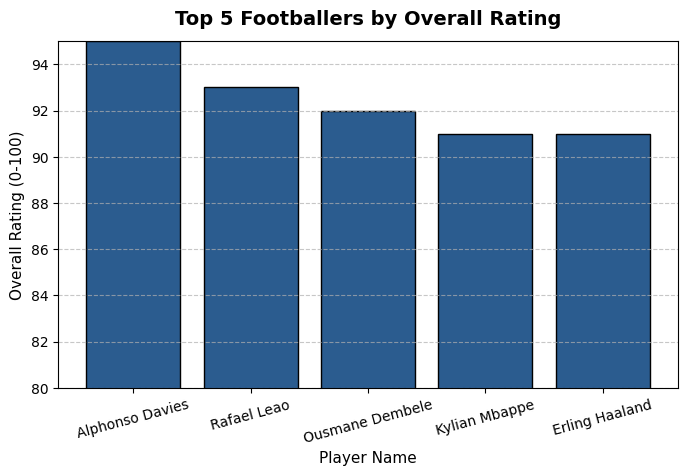

บันทึกกราฟลงไฟล์ top5_overall.png เรียบร้อยแล้ว


In [3]:
# 2.1 สร้าง Bar Chart ด้วย plt.bar()
# หมายเหตุ: แกน X และ แกน Y ต้องมาจากตารางตัวแปรเดียวกัน (top5) เพื่อป้องกัน Error ขนาดไม่เท่ากัน
plt.figure(figsize=(8, 4.5))
plt.bar(top5["name"], top5["overall"], color="#2b5c8f", edgecolor="black")

# 2.2 ปรับแต่งกราฟด้วย Function ต่างๆ
plt.title("Top 5 Footballers by Overall Rating", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Player Name", fontsize=11)
plt.ylabel("Overall Rating (0-100)", fontsize=11)
plt.ylim(80, 95) # กำหนดช่วงแกน Y ให้อ่านความต่างได้ชัดเจน
plt.xticks(rotation=15) # หมุนชื่อแกน X เพื่อไม่ให้ตัวอักษรทับกัน
plt.grid(axis="y", linestyle="--", alpha=0.7)

# 2.3 บันทึกกราฟและแสดงผล
plt.savefig("top5_overall.png", dpi=150, bbox_inches="tight")
plt.show()
print("บันทึกกราฟลงไฟล์ top5_overall.png เรียบร้อยแล้ว")

---
## 3️⃣ ตัวอย่างการสร้างกราฟประเภทอื่นๆ (Histogram & Scatter Plot)
- **Histogram (`plt.hist`)**: ใช้ดูการกระจายตัวของตัวเลข (เช่น อายุ, ค่า overall)
- **Scatter Plot (`plt.scatter`)**: ใช้ดูความสัมพันธ์ระหว่างตัวเลข 2 ชุด


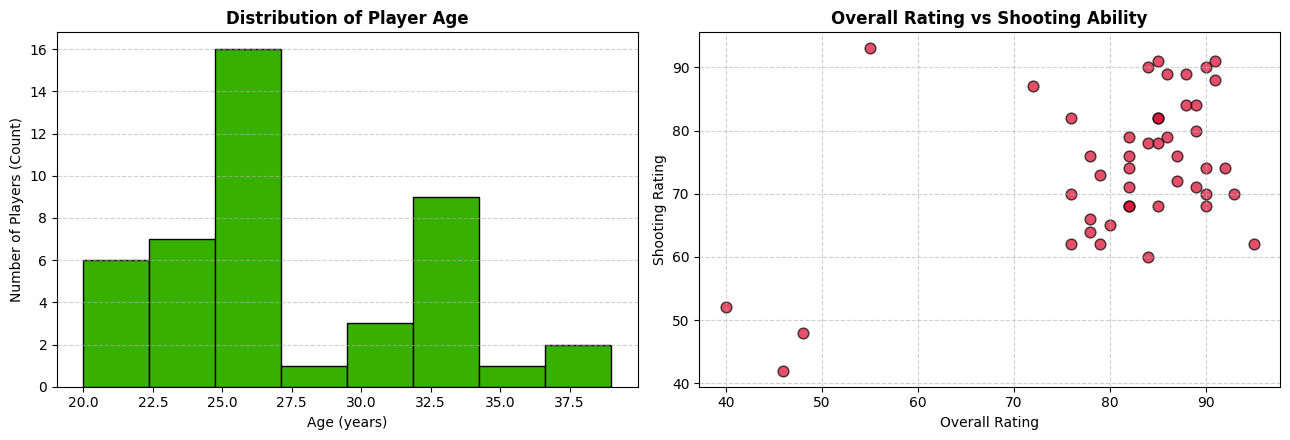

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# 3.1 Histogram: ดูการกระจายตัวของอายุ (Age Distribution)
ax1.hist(df["age"].dropna(), bins=8, color="#38b000", edgecolor="black")
ax1.set_title("Distribution of Player Age", fontsize=12, fontweight="bold")
ax1.set_xlabel("Age (years)")
ax1.set_ylabel("Number of Players (Count)")
ax1.grid(axis="y", linestyle="--", alpha=0.6)

# 3.2 Scatter Plot: ความสัมพันธ์ระหว่าง Overall Rating กับ Shooting
ax2.scatter(df["overall"], df["shooting"], color="#d90429", alpha=0.7, edgecolors="black", s=60)
ax2.set_title("Overall Rating vs Shooting Ability", fontsize=12, fontweight="bold")
ax2.set_xlabel("Overall Rating")
ax2.set_ylabel("Shooting Rating")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()